# ICS 635 · Homework 2
## Fine-Tuning an LLM with LoRA

**Name:** Shea Stevens

Use this notebook to implement your own workflow. Read [ASSIGNMENT.pdf](ASSIGNMENT.pdf) for the
full requirements.

- Keep executable code, outputs, and written analysis here.
- Write concise analysis in Markdown cells beside the relevant results.
- Use `record.md` as optional scratch space; it does not need to be submitted.

Save your completed notebook with outputs.

## Setup

Follow `README.md` to set up the environment with `uv sync --locked` (or install packages manually yourself, listed in `pyproject.toml`).

Run the next three cells as they are. They keep the splits, the prompt format, and the scoring consistent, so that results can be compared.

In [4]:
import re

import torch
from datasets import concatenate_datasets, load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer

SEED = 635 # DO NOT MODIFY
MODEL_NAME = "Qwen/Qwen3-1.7B"
ID_TO_LABEL = {0: "negative", 1: "positive", 2: "neutral"}
LABELS = list(ID_TO_LABEL.values())

device_type = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Device: {device_type}")

Device: cuda


In [5]:
data = load_dataset("zeroshot/twitter-financial-news-sentiment")
train = data["train"].shuffle(seed=SEED)
validation = data["validation"].shuffle(seed=SEED)

lora_train = train.select(range(3000))
example_pool = train.select(range(3000, len(train)))
selection = validation.select(range(600))
test = validation.select(range(600, len(validation)))
all_train = concatenate_datasets([lora_train, example_pool])

for name, part in [("lora_train", lora_train), ("example_pool", example_pool), ("selection", selection), ("test", test)]:
    print(f"{name}: {len(part):,} tweets")

lora_train: 3,000 tweets
example_pool: 6,543 tweets
selection: 600 tweets
test: 1,788 tweets


In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def chat_prompt(content):
    """Wrap one user message in Qwen's chat format, with thinking turned off."""
    return tokenizer.apply_chat_template(
        [{"role": "user", "content": content}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False,
    )


def parse_label(generated):
    """Return the first of "positive", "neutral" or "negative" in the text, ignoring case, or "unparsed"."""
    found = re.search(r"positive|neutral|negative", generated.lower())
    return found.group(0) if found else "unparsed"


def score(predictions, gold):
    """Score predicted label names against true label names. An unparsed output is always wrong."""
    per_class = f1_score(gold, predictions, labels=LABELS, average=None, zero_division=0)
    return {
        "macro_f1": round(float(per_class.mean()), 3),
        "accuracy": round(accuracy_score(gold, predictions), 3),
        **{f"f1_{label}": round(float(f1), 3) for label, f1 in zip(LABELS, per_class)},
        "unparsed": list(predictions).count("unparsed"),
    }


print(chat_prompt("Classify this tweet."))
print(parse_label("Neutral."), parse_label("I am not sure"))

<|im_start|>user
Classify this tweet.<|im_end|>
<|im_start|>assistant
<think>

</think>


neutral unparsed


## 1. Inspect the data

Summarize the labels in all four parts and read the tweets in `lora_train`. Calculate the scores of a method that always answers `neutral`.

**Finish this section:** Show the label table, at least five `lora_train` tweets per label, and the always-`neutral` scores on `selection`. In a Markdown cell below, explain what the label means, name two tweets you would have labeled differently, and explain why macro-F1 is the primary metric.

In [7]:
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", None)

# Number of tweets and the share of each label in all four parts.
parts = {"lora_train": lora_train, "example_pool": example_pool, "selection": selection, "test": test}

rows = []
for name, part in parts.items():
    names = pd.Series(part["label"]).map(ID_TO_LABEL)
    counts = names.value_counts().reindex(LABELS, fill_value=0)
    row = {"split": name, "tweets": len(part)}
    for label in LABELS:
        row[f"{label} n"] = counts[label]
        row[f"{label} %"] = round(100 * counts[label] / len(part), 1)
    rows.append(row)

label_table = pd.DataFrame(rows).set_index("split")
label_table

,tweets,negative n,negative %,positive n,positive %,neutral n,neutral %
split,,,,,,,
lora_train,3000,479,16.0,600,20.0,1921,64.0
example_pool,6543,963,14.7,1323,20.2,4257,65.1
selection,600,103,17.2,129,21.5,368,61.3
test,1788,244,13.6,346,19.4,1198,67.0


In [8]:
# Read tweets from lora_train: a seeded random sample of 8 per label (at least 5 required).
# The index is the tweet's row in lora_train, so a tweet can be referred to in the analysis.
train_df = lora_train.to_pandas()
train_df["label_name"] = train_df["label"].map(ID_TO_LABEL)

TWEETS_PER_LABEL = 8
for label in LABELS:
    sample = train_df[train_df["label_name"] == label].sample(n=TWEETS_PER_LABEL, random_state=SEED)
    print(f"\n=== {label} ===")
    display(sample[["text"]])


=== negative ===


,text
1990,Lifeblood of Amazon merchants threatened as coronavirus infects Chinese workers
2973,Falling Oil Prices An Economic Warning Sign | Zero Hedge https://t.co/M57og3233p
2897,UPDATE 1-California toughens drilling oversight in setback for industry
1775,Policy changes to reduce global warming could force a net $1.6 trillion repricing in sectors from energy to agricul… https://t.co/5c5hIGJcc1
63,$AYX - Alteryx Stock Price: More Downside Before Taking Off. Continue reading: https://t.co/RR0zn7EgmY #business #investing #economy
2791,"$ACM - AECOM: Given Disappointing Earnings And No M&A News, ACM Is A Trading Sell. https://t.co/0QlOr3sV7h #stockmarket #markets #stocks"
2804,Fed's Williams: Risks to U.S. economy still to the downside
1442,Finnair cancels 276 flights as unions join solidarity strike #FinnairOyj #Stock #MarketScreener… https://t.co/j4PMDAs2cI



=== positive ===


,text
337,Tesla shares jump as Musk tweets about Cybertruck preorders
895,"Asia shares bounce, hope for best on U.S.-China trade #economy #MarketScreener https://t.co/j8MxRanCYy https://t.co/WSMCSC8eKo"
2249,After a early morning mishap on $SPY $ZM taking control here with $BA $AAPL $AMZN. $SPY $ZM both would be wins now too.
714,Dunkin' Brands Accelerates Growth Into 2020
2365,"Brighthouse Financial EPS beats by $0.27, beats on revenue"
550,French regulator ends probe into supermarket Casino and short-seller Muddy Waters
2030,Medicines Co. shares jump 17% in premarket after report of potential Novartis offer
82,Amazon to create 500 new jobs in Mississippi as it builds a 2nd fulfillment center in the state



=== neutral ===


,text
985,$BOKF - BOK Financial goes ex-dividend tomorrow https://t.co/GwKBOAPDs5
2827,Turkey is trying to stop emergency loans intended to boost its economy during the coronavirus slowdown from fueling… https://t.co/EcSwShpQGl
1485,Delivery Hero Nears Agreement to Buy Woowa in $4 Billion Deal
2500,This former top Obama official says one silver bullet would raise $500 billion in personal-income tax https://t.co/DgBplbAdCO
169,"Fed bombards credit markets with limitless pledge, but investors barely respond https://t.co/KfTfB94OD1"
2420,Sienna Cancer Diagnostics : Key Terms of CEO/Managing Director Employment Contract #SiennaCancerDiagnostics #Stock… https://t.co/g0J3hXxRYg
397,U.S. total weekly active drilling-rig count unchanged at 790: Baker Hughes
2489,"Market participants submitted bids for nearly twice what was on offer in the Fed’s 42-day term repo operation, whic… https://t.co/qIqTKdQtpk"


In [9]:
# Always answer "neutral" on selection.
selection_gold = [ID_TO_LABEL[label] for label in selection["label"]]
always_neutral = ["neutral"] * len(selection_gold)

pd.DataFrame([score(always_neutral, selection_gold)], index=["always neutral (selection)"])

,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed
always neutral (selection),0.253,0.613,0.0,0.0,0.76,0


### Analysis

TODO: Explain what the label means, name two tweets you would have labeled differently and why, and explain why macro-F1 is the primary metric.

The label indicates the sentiment of a tweet. These tweets are specifically related to the stock market There are three settings, positive, neutral, and negative. Positive denotes good news or happy content and negative discusses tragic or disappointing news. Neutral is a matter-of-fact statement. 

These sentiments are not entirely accurate though.

For instance, 550 reads neutral to me. Through the lens of the stock market though, it's possible to understand the label. The end of a probe is a positive thing for a stock. 
French regulator ends probe into supermarket Casino and short-seller Muddy Waters

1485 can be see as positive. The potential merger/acquisition is often a good time to buy stock of a company, or speculate on options. 
Delivery Hero Nears Agreement to Buy Woowa in $4 Billion Deal


## 2. Establish baselines

Fit a `TfidfVectorizer` and `LogisticRegression(class_weight="balanced")` pipeline on `lora_train`, and again on `all_train`. Score both on `selection`.

**Finish this section:** Show both pipelines, their settings, and a table of scores and training times here. In a Markdown cell below, explain what each baseline tests and what the gap between them says.

In [10]:
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# TODO: Fit both TF-IDF pipelines and measure their training times.

pipe_lora = make_pipeline(TfidfVectorizer(),
                        LogisticRegression(class_weight='balanced', max_iter=1000))
start1 = time.perf_counter()
pipe_lora.fit(lora_train['text'], [ID_TO_LABEL[l] for l in lora_train['label']])
train_seconds_1 = time.perf_counter() - start1
lora_pred = pipe_lora.predict(selection['text'])
print(f"Train time 1: {train_seconds_1:.2f} seconds")

pipe_all = make_pipeline(TfidfVectorizer(),
                        LogisticRegression(class_weight='balanced', max_iter=1000))
start2 = time.perf_counter()
pipe_all.fit(all_train['text'], [ID_TO_LABEL[l] for l in all_train['label']])
train_seconds_2 = time.perf_counter() - start2
all_pred = pipe_all.predict(selection['text'])
print(f"Train time 2: {train_seconds_2:.2f} seconds")


baseline_results = pd.DataFrame(
    [
        {"method": "TF-IDF, lora_train (3,000)", "train_seconds": round(train_seconds_1, 2),
         **score(lora_pred, selection_gold)},
        {"method": "TF-IDF, all_train (9,543)", "train_seconds": round(train_seconds_2, 2),
         **score(all_pred, selection_gold)},
    ]
).set_index("method")
baseline_results

Train time 1: 3.41 seconds
Train time 2: 5.63 seconds


,train_seconds,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed
method,,,,,,,
"TF-IDF, lora_train (3,000)",3.41,0.677,0.745,0.557,0.636,0.838,0
"TF-IDF, all_train (9,543)",5.63,0.739,0.788,0.646,0.710,0.862,0


mkdir -p failed for path /home/vscode/.cache/matplotlib: [Errno 13] Permission denied: '/home/vscode/.cache/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-84i5f2gn because there was an issue with the default path (/home/vscode/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


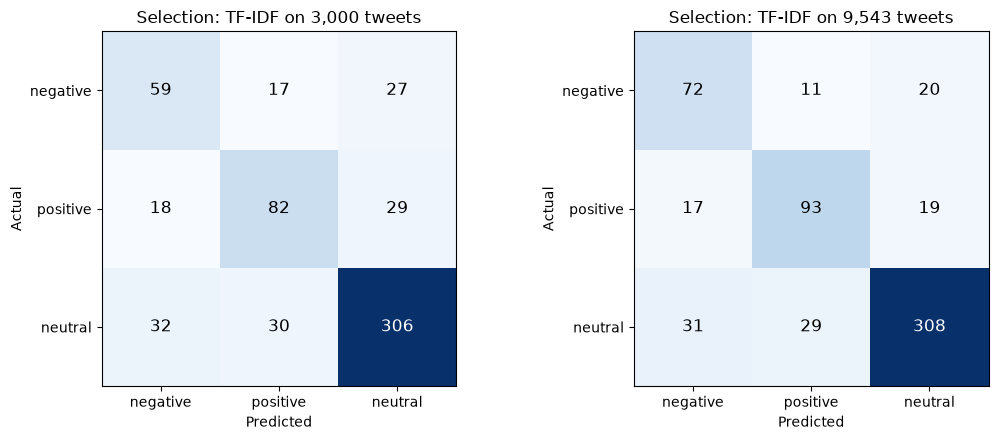

In [11]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt


def plot_confusion(ax, gold, preds, title):
    """Draw a confusion matrix: rows are true labels, columns are predicted labels."""
    # Add an "unparsed" column only if some LLM output didn't parse.
    pred_labels = LABELS + ["unparsed"] if "unparsed" in preds else LABELS
    # Gold labels are never "unparsed", so keep only the 3 real rows.
    cm = confusion_matrix(gold, preds, labels=pred_labels)[: len(LABELS)]

    ax.imshow(cm, cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set(xticks=range(len(pred_labels)), yticks=range(len(LABELS)),
           xticklabels=pred_labels, yticklabels=LABELS,
           xlabel="Predicted", ylabel="Actual", title=title)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(axes[0], selection_gold, list(lora_pred), "Selection: TF-IDF on 3,000 tweets")
plot_confusion(axes[1], selection_gold, list(all_pred), "Selection: TF-IDF on 9,543 tweets")
plt.tight_layout()
plt.show()

### Analysis

TODO: Explain what each baseline tests and what the gap between them says about how much data matters to this method.

The first baseline is for the LoRA data. This is the 3000 tweets that the LoRA model will be trained on. With a logistic regression as a base, this baseline will be used to compare against our more detailed LoRA model. If the scroes improved, it's drectly related to the model and methods that we use.

The second baseline checks how much the initial baseline would improve given more data. Data is often a bottleneck for model performance, so testing with the full dataset reveals whether more data improves the logistic regression. 

From the confustion matrix, we can see that the predicction scores increase for negative (+13) and positive (+11). The neutral score barely moved (+2). From this test, we see that an increase in data quantity improves scores only in minority classes. From the macro F1 scores we see a similar vector. When comparing the improvement between always neutral and baseline 1 which adds 3000 labeled tweets, we see a significant increase of 0.42. But from baseline 1 to baseline 2, which adds 6543 new labeled tweets, we see a much smaller gap of 0.06. There is a definite improvement, but the increase in data has diminishing returns. 

## 3. Prompt the base model

Load the base model and write batched generation code using the fixed settings in the assignment. Remember to pad on the left. Build every prompt with `chat_prompt`.

Write at least two zero-shot and at least four few-shot prompts. Take few-shot examples only from `example_pool`. Include two prompts with the same examples in a different order, and two with the same number of different examples.

**Finish this section:** Show the text of every prompt, with a placeholder where the tweet goes, and one table of `selection` results: macro-F1, accuracy, per-class F1, predicted-label counts, `unparsed` count, and time. Record your best zero-shot and best few-shot prompts, chosen on `selection` macro-F1.

In [ ]:
PROMPTS = {
    "zero_1": "Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: {tweet}. Answer with one word.",
    "zero_2": "How would you classify this finance tweet? {tweet}. Answer with one word: positive, neutral, or negative.",
    # "zero_3": "Describe the outlook of this tweet with one word: {tweet}. Positive, negative, or neutral?"
}

In [13]:
# TODO: Load the base model and write a function that returns the generated text for a list of prompts.
from transformers import AutoModelForCausalLM

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, device_map="auto")
model.eval()


def generate(prompts, batch_size=16, max_new_tokens=6):
    """Greedy-generate a short answer for each prompt string. Returns only the new text."""
    tokenizer.padding_side = "left"
    outputs = []
    for start in range(0, len(prompts), batch_size):
        batch = prompts[start:start + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True,
                           add_special_tokens=False).to(model.device)
        with torch.no_grad():
            generated = model.generate(**inputs, do_sample=False, max_new_tokens=max_new_tokens,
                                       pad_token_id=tokenizer.pad_token_id)
        new_tokens = generated[:, inputs["input_ids"].shape[1]:]
        outputs.extend(tokenizer.batch_decode(new_tokens, skip_special_tokens=True))
    return outputs


def run_prompt(template, tweets, batch_size=16):
    """Fill {tweet} in the template, generate, and return (labels, raw outputs, seconds)."""
    prompts = [chat_prompt(template.replace("{tweet}", tweet)) for tweet in tweets]
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    raw = generate(prompts, batch_size=batch_size)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    return [parse_label(r) for r in raw], raw, seconds

Loading weights: 100%|██████████| 311/311 [00:02<00:00, 124.31it/s]
Some parameters are on the meta device because they were offloaded to the cpu.


In [14]:
pool_df = example_pool.to_pandas()
pool_df["label_name"] = pool_df["label"].map(ID_TO_LABEL)


def sample_examples(per_label, seed, exclude=()):
    """Pick per_label tweets of each label from example_pool, then shuffle so labels aren't grouped."""
    candidates = pool_df.drop(index=list(exclude))
    picked = candidates.groupby("label_name", group_keys=False).sample(n=per_label, random_state=seed)
    return picked.sample(frac=1, random_state=seed)


def few_shot_template(instruction, examples):
    """Instruction, then each example as Tweet/Answer, then the {tweet} placeholder."""
    parts = [instruction, ""]
    for text, label in zip(examples["text"], examples["label_name"]):
        parts.append(f"Tweet: {' '.join(text.split())}\nAnswer: {label}\n")
    parts.append("Tweet: {tweet}\nAnswer:")
    return "\n".join(parts)

INSTRUCTION = "Classify the outlook of each finance tweet as positive, negative, or neutral. Answer with one word."

set_A = sample_examples(per_label=2, seed=SEED)                               # 6 examples
set_B = sample_examples(per_label=2, seed=SEED + 1, exclude=set_A.index)      # 6 different examples

PROMPTS["few_A"] = few_shot_template(INSTRUCTION, set_A)
PROMPTS["few_A_reversed"] = few_shot_template(INSTRUCTION, set_A.iloc[::-1])  # same tweets, reversed order
PROMPTS["few_B"] = few_shot_template(INSTRUCTION, set_B)                      # same count, different tweets

In [15]:
from collections import Counter

for name, template in PROMPTS.items():
    print(f"=== {name} ===\n{template}\n")

generate([chat_prompt("Warm-up.")] * 4)   # first call is slow; don't let it inflate prompt 1's time

rows, outputs = [], {}
for name, template in PROMPTS.items():
    batch_size = 4 if name.startswith("few_") else 16   # long prompts need smaller batches on 10 GB
    preds, raw, seconds = run_prompt(template, selection["text"], batch_size=batch_size)
    outputs[name] = {"pred": preds, "raw": raw}
    pd.DataFrame({"text": selection["text"], "gold": selection_gold, "pred": preds, "raw": raw}) \
        .to_csv(f"selection_{name}.csv", index=False)   # saved as you go, in case the kernel dies

    counts = Counter(preds)
    rows.append({
        "prompt": name,
        **score(preds, selection_gold),
        **{f"n_{label}": counts.get(label, 0) for label in LABELS},
        "seconds": round(seconds, 1),
    })
    print(f"{name}: macro-F1 {rows[-1]['macro_f1']}, {seconds:.0f}s")

prompt_results = pd.DataFrame(rows).set_index("prompt")
prompt_results

=== zero_1 ===
Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: {tweet}. Answer with one word.

=== zero_2 ===
How would you classify this finance tweet? {tweet}. Answer with one word: positive, neutral, or negative.

=== few_A ===
Classify the outlook of each finance tweet as positive, negative, or neutral. Answer with one word.

Tweet: U.S. economy adds 225,000 jobs in January; 2019 annual figure revised downward
Answer: positive

Tweet: Boston Scientific $BSX more bullish flow with 5000 May $30 puts being sold $0.72 and the August $40 calls bought $1.30
Answer: positive

Tweet: Egypt's inflation inched higher for a third straight month in urban parts of the country https://t.co/DoJPWNnsC1
Answer: negative

Tweet: Steris declares $0.37 dividend
Answer: neutral

Tweet: $FLOW: SPX FLOW confirms deal to sell substantial portion of former Power and Energy reportable segment to Apollo... https://t.co/THAiKLuD8X
Answer: neutral

Tweet: March WTI oil cont

/workspaces/ics635-assignment2/.venv/lib/python3.13/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


zero_1: macro-F1 0.627, 33s
zero_2: macro-F1 0.555, 45s
few_A: macro-F1 0.732, 285s
few_A_reversed: macro-F1 0.662, 309s
few_B: macro-F1 0.628, 109s


,macro_f1,accuracy,f1_negative,f1_positive,f1_neutral,unparsed,n_negative,n_positive,n_neutral,seconds
prompt,,,,,,,,,,
zero_1,0.627,0.622,0.667,0.596,0.618,0,161,237,202,32.9
zero_2,0.555,0.525,0.690,0.530,0.444,0,129,339,132,45.3
few_A,0.732,0.743,0.743,0.667,0.787,13,142,132,313,285.1
few_A_reversed,0.662,0.668,0.659,0.603,0.725,15,64,249,272,309.4
few_B,0.628,0.605,0.719,0.557,0.607,6,100,295,199,109.2


### Analysis

TODO: Explain which prompt changes mattered, what the order and different-example pairs show, and which two prompts you chose and why.

## 4. Fine-tune with LoRA

Train on `lora_train` with the fixed settings, using your best zero-shot prompt in each training example. Each example is the prompt, the label, and `<|im_end|>\n`. Remember to pad on the right for training and return to left padding for generation.

**Finish this section:** Show the configuration, one complete training example, the trainable parameter count and percentage, training time, peak GPU memory, adapter size, start and end loss, a plot of the training loss, and the `selection` scores of the model reloaded from its saved adapter.

In [25]:
from datasets import Dataset

BEST_ZERO_SHOT_NAME = "zero_1"   # TODO: confirm from the full cell-19 table (zero_3 not scored yet)
BEST_ZERO_SHOT = PROMPTS[BEST_ZERO_SHOT_NAME]


def training_text(tweet, label_id):
    """The generation prompt, then the label, then the end-of-turn token."""
    return chat_prompt(BEST_ZERO_SHOT.replace("{tweet}", tweet)) + ID_TO_LABEL[label_id] + "<|im_end|>\n"


texts = [training_text(t, l) for t, l in zip(lora_train["text"], lora_train["label"])]
# Tokenize here: TRL appends <|im_end|> to any "text" that doesn't end with it, and ours ends with "\n".
# A dataset that already has input_ids skips that step, so the model trains on exactly these tokens.
train_dataset = Dataset.from_dict({
    "text": texts,
    "input_ids": [tokenizer(t, add_special_tokens=False)["input_ids"] for t in texts],
})

lengths = [len(ids) for ids in train_dataset["input_ids"]]
print(f"{len(train_dataset)} examples; tokens max {max(lengths)}, mean {sum(lengths) / len(lengths):.0f} (max_length=256)\n")

example = tokenizer.decode(train_dataset[0]["input_ids"])
print(example)
assert example.endswith(ID_TO_LABEL[lora_train[0]["label"]] + "<|im_end|>\n")


3000 examples; tokens max 120, mean 64 (max_length=256)

<|im_start|>user
Classify the outlook of this finance tweet as positive, neutral, or negative. Tweet: Sports Direct International : Britain's Sports Direct to change name to Frasers Group ...… https://t.co/dgK2Mb3MbE. Answer with one word.<|im_end|>
<|im_start|>assistant
<think>

</think>

neutral<|im_end|>



In [ ]:
# TODO: Apply LoraConfig with get_peft_model and report the trainable parameters.
# TODO: Train with SFTTrainer and measure training time and peak memory.
# TODO: Plot the training loss from trainer.state.log_history.

import gc
import os

import matplotlib.pyplot as plt
from peft import LoraConfig, get_peft_model
from transformers import set_seed
from trl import SFTConfig, SFTTrainer

DEV_RUN = False   # True = bf16 + 64 examples, to smoke-test on the 8 GB card. Must be False for real results.
TARGET_MODULES = ["k_proj", "gate_proj", "v_proj", "up_proj", "q_proj", "o_proj", "down_proj"]


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def train_lora(r, lora_alpha, output_dir, dataset=train_dataset):
    """Train one LoRA adapter with the fixed settings, save it, and return its costs and loss history."""
    set_seed(SEED)
    tokenizer.padding_side = "right"   # right padding for training
    if DEV_RUN:
        dataset = dataset.select(range(64))

    base = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, dtype=torch.bfloat16 if DEV_RUN else torch.float32, device_map="auto")
    lora_config = LoraConfig(r=r, lora_alpha=lora_alpha, lora_dropout=0.1, bias="none",
                             task_type="CAUSAL_LM", target_modules=TARGET_MODULES)
    peft_model = get_peft_model(base, lora_config)
    trainable, total = peft_model.get_nb_trainable_parameters()

    training_args = SFTConfig(
        output_dir=output_dir,
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        optim="adamw_torch", learning_rate=2e-4, lr_scheduler_type="cosine", num_train_epochs=1,
        bf16=True, dataset_text_field="text", max_length=256,
        save_strategy="no", report_to="none", seed=SEED,
        logging_steps=1,   # log every optimizer step so the start/end loss is exact
    )
    trainer = SFTTrainer(model=peft_model, args=training_args, train_dataset=dataset,
                         processing_class=tokenizer)

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    torch.cuda.synchronize()
    train_seconds = time.perf_counter() - start
    peak_gb = torch.cuda.max_memory_allocated() / 1e9

    peft_model.save_pretrained(output_dir)   # saves only the adapter weights and config
    adapter_mb = os.path.getsize(os.path.join(output_dir, "adapter_model.safetensors")) / 1e6
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]

    stats = {"r": r, "lora_alpha": lora_alpha, "scaling": lora_alpha / r,
             "trainable_params": trainable, "trainable_pct": round(100 * trainable / total, 3),
             "train_seconds": round(train_seconds, 1), "peak_gb": round(peak_gb, 2),
             "adapter_mb": round(adapter_mb, 1),
             "loss_start": round(losses[0][1], 4), "loss_end": round(losses[-1][1], 4)}

    del trainer, peft_model, base
    free_gpu()
    tokenizer.padding_side = "left"   # back to left padding for generation
    return stats, losses, lora_config, training_args


# Release the Section 3 base model first: two float32 copies won't fit.
if "model" in globals():
    del model
free_gpu()

ADAPTER_DIR = "adapters/lora_r64_a32"
lora_stats, lora_losses, lora_config, training_args = train_lora(r=64, lora_alpha=32, output_dir=ADAPTER_DIR)

print(lora_config)
print({k: getattr(training_args, k) for k in [
    "per_device_train_batch_size", "gradient_accumulation_steps", "optim", "learning_rate",
    "lr_scheduler_type", "num_train_epochs", "bf16", "max_length", "gradient_checkpointing", "seed"]})
display(pd.DataFrame([lora_stats]))

steps, loss = zip(*lora_losses)
smooth = pd.Series(loss).rolling(20, min_periods=1).mean()
plt.figure(figsize=(8, 4))
plt.plot(steps, loss, alpha=0.3, label="per step")
plt.plot(steps, smooth, label="20-step mean")
plt.xlabel("optimizer step")
plt.ylabel("training loss")
plt.title("LoRA r=64, alpha=32 on lora_train")
plt.legend()
plt.show()


In [ ]:
# TODO: Save the adapter, release the model, and report the adapter size on disk.
# TODO: Reload it with AutoPeftModelForCausalLM and score it on selection.

from peft import AutoPeftModelForCausalLM

print(f"Adapter on disk: {lora_stats['adapter_mb']} MB")

# Load from disk, not the in-memory model, to confirm what was saved is what was trained.
model = AutoPeftModelForCausalLM.from_pretrained(ADAPTER_DIR, dtype=torch.float32, device_map="auto")
model.eval()

lora_preds, lora_raw, lora_seconds = run_prompt(BEST_ZERO_SHOT, selection["text"])
pd.DataFrame([{**score(lora_preds, selection_gold), "seconds": round(lora_seconds, 1)}],
             index=[f"LoRA r=64, alpha=32 ({BEST_ZERO_SHOT_NAME} prompt), selection"])


### Analysis

TODO: Explain what LoRA trains and what stays frozen, why the adapter is so much smaller than the model, and what the loss curve shows.

## 5. Compare LoRA settings

Run the other four settings from the assignment's table, resetting the seed and loading a fresh base model each time. You already ran the first (`r=64`, `lora_alpha=32`) in Section 4. Save each adapter under its own name.

**Finish this section:** Show one table with all five runs (trainable parameters, adapter size, training time, peak memory, and `selection` scores) and a plot of macro-F1 against rank with two lines, one for `lora_alpha = r / 2` and one for `lora_alpha = 32`. The rank-64 point belongs on both lines, since 32 = 64 / 2. Record your final setting and the rule you used to choose it.

In [ ]:
from peft import AutoPeftModelForCausalLM


def score_adapter(adapter_dir, name):
    """Reload a saved adapter onto a fresh base model, score it on selection, save its outputs, then free it."""
    global model   # generate()/run_prompt() read the global model
    model = AutoPeftModelForCausalLM.from_pretrained(
        adapter_dir, dtype=torch.bfloat16 if DEV_RUN else torch.float32, device_map="auto")
    model.eval()
    preds, raw, seconds = run_prompt(BEST_ZERO_SHOT, selection["text"])
    pd.DataFrame({"text": selection["text"], "gold": selection_gold, "pred": preds, "raw": raw}) \
        .to_csv(f"selection_{name}.csv", index=False)
    del model
    free_gpu()
    return preds, seconds


print(f"Adapter on disk: {lora_stats['adapter_mb']} MB")
# Load from disk, not the in-memory model, to confirm what was saved is what was trained.
lora_preds, lora_seconds = score_adapter(ADAPTER_DIR, "lora_r64_a32")
pd.DataFrame([{**score(lora_preds, selection_gold), "seconds": round(lora_seconds, 1)}],
             index=[f"LoRA r=64, alpha=32 ({BEST_ZERO_SHOT_NAME} prompt), selection"])


In [ ]:
SETTINGS = [(16, 8), (4, 2), (16, 32), (4, 32)]   # (r, lora_alpha); (64, 32) was run in Section 4

lora_runs = [{**lora_stats, **score(lora_preds, selection_gold), "predict_seconds": round(lora_seconds, 1)}]
loss_histories = {"r64_a32": lora_losses}

for r, alpha in SETTINGS:
    name = f"r{r}_a{alpha}"
    print(f"\n=== Training {name} ===")
    stats, losses, _, _ = train_lora(r=r, lora_alpha=alpha, output_dir=f"adapters/lora_{name}")
    preds, seconds = score_adapter(f"adapters/lora_{name}", f"lora_{name}")
    lora_runs.append({**stats, **score(preds, selection_gold), "predict_seconds": round(seconds, 1)})
    loss_histories[name] = losses
    pd.DataFrame(lora_runs).to_csv("lora_runs.csv", index=False)   # saved as you go, in case the kernel dies
    print(f"{name}: macro-F1 {lora_runs[-1]['macro_f1']}, train {stats['train_seconds']}s, peak {stats['peak_gb']} GB")


In [ ]:
runs = pd.DataFrame(lora_runs).set_index(["r", "lora_alpha"])
display(runs[["scaling", "trainable_params", "trainable_pct", "adapter_mb", "train_seconds", "peak_gb",
              "loss_start", "loss_end", "macro_f1", "accuracy",
              "f1_negative", "f1_positive", "f1_neutral", "unparsed"]])

f1 = runs["macro_f1"]
half = [(r, f1[(r, r // 2)]) for r in (4, 16, 64)]   # lora_alpha = r / 2 (scaling 0.5)
fixed = [(r, f1[(r, 32)]) for r in (4, 16, 64)]      # lora_alpha = 32 (scaling 8, 2, 0.5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(*zip(*half), marker="o", label="lora_alpha = r / 2 (scaling 0.5)")
axes[0].plot(*zip(*fixed), marker="s", label="lora_alpha = 32 (scaling 32 / r)")
axes[0].set(xscale="log", xticks=[4, 16, 64], xticklabels=["4", "16", "64"],
            xlabel="LoRA rank r", ylabel="selection macro-F1", title="Selection macro-F1 vs. rank")
axes[0].legend()

for name, losses in loss_histories.items():
    steps, loss = zip(*losses)
    axes[1].plot(steps, pd.Series(loss).rolling(20, min_periods=1).mean(), label=name)
axes[1].set(xlabel="optimizer step", ylabel="training loss (20-step mean)", title="Training loss, all five runs")
axes[1].legend()
plt.tight_layout()
plt.show()


### Analysis

TODO: Explain what rank and scaling each did to the score and the cost, which setting you chose and why, and how much a single seed and 600 tweets limit what you can conclude.

## Before final evaluation: record your final choices

Complete this checklist before proceeding to Section 6.

- [ ] Both TF-IDF pipelines are fitted and will not be changed.
- [ ] The best zero-shot and few-shot prompts are chosen and recorded.
- [ ] The final LoRA setting is chosen and its adapter is saved.
- [ ] Final prompts and the LoRA setting were chosen on `selection`; nothing used `test`.

| Method | Final configuration |
|---|---|
| TF-IDF on 3,000 tweets | TODO |
| TF-IDF on 9,543 tweets | TODO |
| Best zero-shot prompt | TODO |
| Best few-shot prompt | TODO |
| Final LoRA `r` and `lora_alpha` | TODO |

Do not revise these choices after inspecting test results.

## 6. Evaluate once on the test set

Score the six methods on `test` once each. Load the fine-tuned model from its saved adapter. Save the tweets, true labels, and every method's predictions as `test_predictions.csv`, and calculate the final metrics from that table.

**Finish this section:** Show one comparison table (macro-F1, accuracy, per-class F1, `unparsed` count, and prediction time per 1,000 tweets) and confusion matrices for the best zero-shot prompt and the fine-tuned model. Label every result as a test result.

In [ ]:
# Generate test predictions for all six methods and measure prediction time.
# Save test_predictions.csv with one row per tweet.

# Final choices, copied from the checklist above. All were chosen on selection; do not change them after this runs.
BEST_FEW_SHOT_NAME = "few_A"   # best few-shot macro-F1 on selection (0.732)
FINAL_R, FINAL_ALPHA = 64, 32  # TODO: set from the Section 5 table
FINAL_ADAPTER_DIR = f"adapters/lora_r{FINAL_R}_a{FINAL_ALPHA}"
assert os.path.exists(os.path.join(FINAL_ADAPTER_DIR, "adapter_model.safetensors")), FINAL_ADAPTER_DIR
assert not DEV_RUN, "DEV_RUN adapters are smoke tests, not final models"

test_tweets = list(test["text"])
test_gold = [ID_TO_LABEL[label] for label in test["label"]]

METHODS = {   # column name in test_predictions.csv -> display name
    "always_neutral": "1. Always neutral",
    "tfidf_3000": "2. TF-IDF on 3,000 tweets",
    "tfidf_9543": "3. TF-IDF on 9,543 tweets",
    "zero_shot": f"4. Best zero-shot ({BEST_ZERO_SHOT_NAME})",
    "few_shot": f"5. Best few-shot ({BEST_FEW_SHOT_NAME})",
    "lora": f"6. LoRA r={FINAL_R}, alpha={FINAL_ALPHA}",
}
test_preds, test_seconds = {}, {}


def save_test_predictions():
    """Write every method finished so far, so a crashed kernel doesn't lose the LLM runs."""
    pd.DataFrame({"text": test_tweets, "gold": test_gold, **test_preds}).to_csv("test_predictions.csv", index=False)


def timed(fn):
    start = time.perf_counter()
    result = fn()
    return result, time.perf_counter() - start


# Methods 1-3: no GPU. The TF-IDF pipelines are the ones fitted in Section 2; they are not refit.
test_preds["always_neutral"], test_seconds["always_neutral"] = timed(lambda: ["neutral"] * len(test_tweets))
for col, pipe in [("tfidf_3000", pipe_lora), ("tfidf_9543", pipe_all)]:
    preds, test_seconds[col] = timed(lambda: list(pipe.predict(test_tweets)))
    test_preds[col] = preds
save_test_predictions()

# Methods 4-5: the base model, with the same batch sizes as in Section 3.
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32, device_map="auto")
model.eval()
generate([chat_prompt("Warm-up.")] * 4)   # keep the first-call cost out of the timing
for col, name, batch_size in [("zero_shot", BEST_ZERO_SHOT_NAME, 16), ("few_shot", BEST_FEW_SHOT_NAME, 4)]:
    preds, raw, test_seconds[col] = run_prompt(PROMPTS[name], test_tweets, batch_size=batch_size)
    test_preds[col] = preds
    test_preds[f"{col}_raw"] = raw
    save_test_predictions()
    print(f"{METHODS[col]}: {test_seconds[col]:.0f}s")
del model
free_gpu()

# Method 6: the fine-tuned model, loaded from its saved adapter, with the zero-shot prompt it was trained on.
model = AutoPeftModelForCausalLM.from_pretrained(FINAL_ADAPTER_DIR, dtype=torch.float32, device_map="auto")
model.eval()
generate([chat_prompt("Warm-up.")] * 4)
preds, raw, test_seconds["lora"] = run_prompt(BEST_ZERO_SHOT, test_tweets, batch_size=16)
test_preds["lora"], test_preds["lora_raw"] = preds, raw
save_test_predictions()
print(f"{METHODS['lora']}: {test_seconds['lora']:.0f}s")
del model
free_gpu()

print(f"Saved test_predictions.csv: {len(test_tweets)} tweets, columns {list(pd.read_csv('test_predictions.csv').columns)}")

In [ ]:
# Calculate the scores and confusion matrices from test_predictions.csv, and add the prediction times measured above.

# keep_default_na=False: a tweet or raw output like "NA" or "None" stays a string instead of becoming NaN.
results = pd.read_csv("test_predictions.csv", keep_default_na=False)
assert len(results) == len(test) and list(results["gold"]) == test_gold

test_rows = []
for col, name in METHODS.items():
    test_rows.append({
        "method (test)": name,
        **score(list(results[col]), list(results["gold"])),
        "seconds_per_1000": round(1000 * test_seconds[col] / len(results), 2),
    })
test_results = pd.DataFrame(test_rows).set_index("method (test)")
display(test_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_confusion(axes[0], list(results["gold"]), list(results["zero_shot"]), f"Test: {METHODS['zero_shot']}")
plot_confusion(axes[1], list(results["gold"]), list(results["lora"]), f"Test: {METHODS['lora']}")
plt.tight_layout()
plt.show()

### Analysis

TODO: Compare the test results with selection, describe what changed between the two confusion matrices, and explain how the methods rank.

## 7. Analyze the failures

Read the errors. They come from `test`, so use them to explain your results and inform your recommendation, not to change any prompt or model.

**Finish this section:** Define at least three slices of `test`, and report the number of tweets and the macro-F1 of methods 3, 4 and 6 on each slice and on the rest of `test`. Find the tweets that methods 2 to 6 all got wrong, read at least 15 of them chosen with seed 635, mark each as mislabeled, ambiguous or hard with one line on why, and count the marks.

In [23]:
# TODO: Define at least three slices of test. For each slice and the rest of test, report the number of tweets and the macro-F1 of methods 3, 4 and 6.

In [24]:
# TODO: Find the tweets that methods 2 to 6 all got wrong and report how many there are.
# TODO: Read at least 15 of them, chosen with seed 635; mark each as mislabeled, ambiguous or hard, and count the marks.

### Analysis

TODO: Explain where fine-tuning's lead grows or shrinks across your slices and whether each slice is large enough to trust the difference, and what the tweets every method got wrong say about the labels.

### Recommendation

TODO: Someone needs to label this kind of tweet at scale. Using the scores, the training costs from Sections 2, 4 and 5, the prediction times from Section 6, and your error analysis, say which method you would choose and what would change your mind.